In [1]:
# 그래프 관련
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
# matplotlib.rcParams['font.family'] = 'AppleGothic'
matplotlib.rcParams['axes.unicode_minus']=False

import pandas as pd
import numpy as np

# 머신러닝 관련
from sklearn import svm,metrics
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier  #평균절대값오차
from sklearn.neighbors import KNeighborsRegressor
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error

In [42]:
df = pd.read_csv('data/score.csv')
df

,hour,score
0,0.5,10
1,1.2,8
2,1.8,14
3,2.4,26
4,2.6,22
5,3.2,30
6,3.9,42
7,4.4,48
8,4.5,38
9,5.0,58


In [34]:
hour = np.array(df['hour']).reshape(-1, 1)
score = np.array(df['score'])

In [35]:
train_data,test_data,train_label,test_label = \
    train_test_split(hour,score)

In [47]:
lr = LinearRegression()
lr.fit(train_data, train_label)
predict = lr.predict(test_data)
print('점수예측: ', predict)
score = lr.score(train_data, train_label)
score2 = lr.score(test_data, test_label)
print(f'정확도:{score*100}%, {score2*100}*')

점수예측:  [73.62124331 24.6319473  46.40496775 92.12831069 89.95100865]
정확도:95.90170891823495%, 90.63270388119436*


예측점수: [85.59640456]


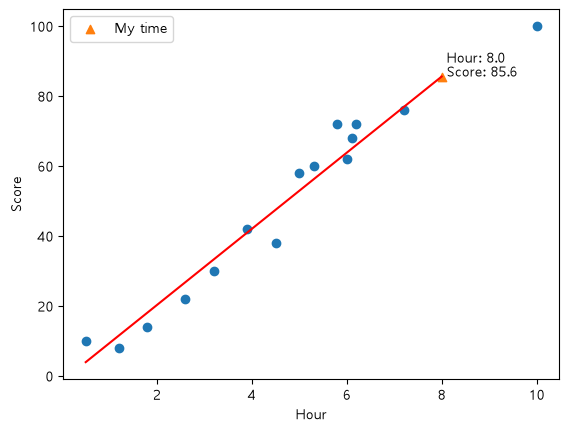

In [48]:
# 길이를 입력받아 무게 예측하기
i_data = input('공부시간:')
i_data = float(i_data)
predict = lr.predict([[i_data]])
print('예측점수:',predict)

# 삼점도 그래프
plt.scatter(train_data,train_label)
plt.plot([0.5,i_data],[0.5 * lr.coef_ + lr.intercept_, i_data * lr.coef_ + lr.intercept_], color='red')
plt.scatter(i_data,predict, marker='^', label='My time')
plt.text(i_data, predict[0], f' Hour: {i_data}\n Score: {predict[0]:.1f}')
plt.xlabel('Hour')
plt.ylabel('Score')
plt.legend()
plt.show()